# **CAPSTONE PROJECT **

# PHASE 1: BUSINESS UNDERSTANDING

Dataset: TeleConnect Customer Data
Business Context: You are a junior data analyst at TeleConnect, a telecommunications company facing customer retention challenges. The Customer Experience team needs to understand who is leaving, what patterns exist, and what actions can improve retention.
---

# **Mission**
*   Who are our customers? (demographics, behaviors)
*   Which services drive loyalty?
*   How do contracts and payments affect retention?
*   What specific actions should we take?
---

# **Learning Objectives**
*   Data Cleaning with Pandas (handling missing values, data types, duplicates)
*   Data Manipulation (filtering, grouping, aggregating, feature engineering)
*   Exploratory Data Analysis (uncovering patterns and relationships)
*   Descriptive Statistics (mean, median, std dev, distributions, percentiles)
*   Data Visualization with Matplotlib & Seaborn
*   Business Communication (CRISP-DM methodology, professional reports)
*   Critical Thinking (pattern recognition, evidence-based recommendations.






# PHASE 2: DATA UNDERSTANDING
# ** 🧹Part 1: Data Preparation & Cleaning (20 points)**

---



Load, inspect, and clean the TeleConnect dataset. Handle missing values,
correct data types, and engineer new features that reveal deeper insights.
Document every decision you make.

# **1.1 Import Libraries and set up environment for data analysis**

Import all the vital libraries necessary for reading, inspecting and organizing the data. Import Pandas for handling datasets, tables, and data cleaning; NumPy to  enable numerical operations and working with arrays; Matplotlib’s pyplot to enable visualizations; Seaborn to enhance visualization by enabling stylizing of our statistical charts and plots; SQLite3 to enable connecting to and querying SQLite database; Datetime will enable converting dates from other datatypes to the python dates class; Warnings module that tells Python to ignore warning messages and keep clean outputs and plots.

Set the seaborn visualization to a white background and grid lines.
Set the figure of matplotlib plots to a size of 12inches wide and 6inches high.

In [19]:
# 1.1 Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from datetime import datetime
import warnings
warnings.filterwarnings("ignore")

# Set visualization Style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("✓ Libraries imported successfully!")



✓ Libraries imported successfully!


# **1.2 Load and preview the dataset**
While there are various ways of loading dataset into colab, it is important to use a method that allows for collaboration with other programmers. In this case, there is no collaboration, but this project has to be viewed and perhaps commented on by the supervisor. As such, it is important to use an approach that ensures that the other user can access the dataset without loading it from their local drive.

**Uploading Dataset directly from the computer to google colab**is an unreliable approach as other collaborators must have a copy of the dataset on their local drive to repeatedly upload it before inspecting.

The google colab **"Drive Mount"** imports Google Drive into this Colab notebook and enables access of the dataset stored in the Google Drive as if it is part of the local file system. This method does not require repeat uploading of dataset to colab.

Another option is using a **shareable google drive link** to enhance collaboration. Anyone with the link can be able to view, edit, or comment on both the notebook and the dataset depending on the share permission set by the author.

Uploading the data set to a github repository is also a good option that not only permits for collaboration.

In [20]:
# Upload dataset directly from the computer to google colab.
# Uncomment the code below

# from google.colab import files
# uploaded = files.upload()

# df = pd.read_csv("teleconnect_customer_data.csv")
# print("✓ Dataset loaded successfully!")

In [21]:
# from google.colab import drive
# drive.mount("/content/drive")

# df = pd.read_csv("/content/drive/MyDrive/MonicaNyagaya_CapstoneProject/teleconnect_customer_data.csv")
# print("✓ Dataset loaded successfully!")

In [22]:
# Load and access the dataset from github repository using raw link
# First, I created a github repository and uploaded the dataset. Then copied the raw github url of the dataset and pasted below.
# https://raw.githubusercontent.com/nyagayamonica-droid/TeleConnect_Capstone/refs/heads/main/data/teleconnect_customer_data.csv?token=GHSAT0AAAAAADPKOMOJZACSVUTQKY4OFOJQ2JKAGRA

# NOTE: Github tokens usually expire and the above link may not work when token expires. So, the url token should be ommited and define the url as below.
# Uncomment the code below

# url = "https://raw.githubusercontent.com/nyagayamonica-droid/TeleConnect_Capstone/refs/heads/main/data/teleconnect_customer_data.csv"

# df = pd.read_csv(url)

# print("✓ Dataset loaded successfully!")

In [23]:
# Load and access the dataset using a shareable google drive link
# Original google shareable link for the dataset is:  https://drive.google.com/file/d/14OaA_oFCqR5rL4RxRB-YyKnVilKT9npA/view?usp=sharing
# Convert the google link to a downloadable url: https://drive.google.com/uc?id=14OaA_oFCqR5rL4RxRB-YyKnVilKT9npA
# Uncomment the code below for results

# url = "https://drive.google.com/uc?id=14OaA_oFCqR5rL4RxRB-YyKnVilKT9npA"

# df = pd.read_csv(url)

# print("✓ Dataset loaded successfully!")

In [24]:
df = pd.read_csv("data/teleconnect_customer_data.csv")
print("✓ Dataset loaded successfully!")

✓ Dataset loaded successfully!


# **1.3 Inspect the dataset**
This section includes:

**The dataset shape**

**the columns**

**The Data types**

**The statistical summary**




In [25]:
# Check the structure of the dataset.

print("Dataset Shape:", df.shape)
print("\nColumn Names and Types:")
print(df.dtypes)
print("\nFirst rows:")
df.head(6)

Dataset Shape: (7043, 21)

Column Names and Types:
customer_id           object
gender                object
senior_citizen        object
partner               object
dependents            object
tenure_months          int64
phone_service         object
multiple_lines        object
internet_service      object
online_security       object
online_backup         object
device_protection     object
tech_support          object
streaming_tv          object
streaming_movies      object
contract_type         object
paperless_billing     object
payment_method        object
monthly_charges      float64
total_charges        float64
customer_status       object
dtype: object

First rows:


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,customer_status
0,CUST00001,Male,Yes,No,No,11,No,No phone service,DSL,No,...,No,No,Yes,Yes,One year,Yes,Bank transfer (automatic),4008.19,44090.09,Active
1,CUST00002,Female,No,Yes,No,10,Yes,Yes,DSL,No,...,Yes,Yes,No,No,Month-to-month,No,Mailed check,4409.39,44093.90,Churned
2,CUST00003,Female,No,Yes,Yes,12,Yes,No,Fiber optic,No,...,Yes,No,No,No,Two year,Yes,Credit card (automatic),4486.64,53839.68,Active
3,CUST00004,Female,No,No,No,70,Yes,No,DSL,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,4512.78,315894.60,Active
4,CUST00005,Male,Yes,No,No,36,Yes,Yes,Fiber optic,Yes,...,No,No,Yes,No,Month-to-month,No,Bank transfer (automatic),6163.53,221887.08,Churned
5,CUST00006,Male,No,Yes,No,5,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Bank transfer (automatic),2741.73,13708.65,Churned


In [26]:
# Display column information
print("Teleconnect Customer Analysis Columns Details:")
print("-" * 50)
for col in df.columns:
    print(f"{col}: {df[col].dtype}")
    print(f"  Unique values: {df[col].nunique()}")
    print(f"  Missing values: {df[col].isna().sum()}")
    print()

Teleconnect Customer Analysis Columns Details:
--------------------------------------------------
customer_id: object
  Unique values: 7043
  Missing values: 0

gender: object
  Unique values: 2
  Missing values: 0

senior_citizen: object
  Unique values: 2
  Missing values: 0

partner: object
  Unique values: 2
  Missing values: 0

dependents: object
  Unique values: 2
  Missing values: 0

tenure_months: int64
  Unique values: 72
  Missing values: 0

phone_service: object
  Unique values: 2
  Missing values: 0

multiple_lines: object
  Unique values: 3
  Missing values: 0

internet_service: object
  Unique values: 3
  Missing values: 0

online_security: object
  Unique values: 3
  Missing values: 0

online_backup: object
  Unique values: 3
  Missing values: 0

device_protection: object
  Unique values: 3
  Missing values: 0

tech_support: object
  Unique values: 3
  Missing values: 0

streaming_tv: object
  Unique values: 3
  Missing values: 0

streaming_movies: object
  Unique values

# Summary of structure
**The dataset structure**

The Teleconnect Capstone dataset has 21 columns and 7042 rows. Each row represents a customer.

**The Data types**
There are two columns whose datatypes are floats: monthly_charges and total_charges
One column has integers: tenure_months
All the other 18 columns have string datatype.

**Missing Values**
The total_charges column has 11 missing values.







# Statistical summary for numerical columns

In [27]:
# Summary statistics for numeric columns.
df.describe()

,tenure_months,monthly_charges,total_charges
count,7043.000000,7043.000000,7032.000000
mean,26.385773,4692.726706,124037.389150
std,20.154208,1262.788244,103759.012631
min,1.000000,1805.910000,1942.930000
25%,9.000000,3737.755000,39961.920000
50%,22.000000,4900.670000,94691.525000
75%,39.000000,5622.675000,182561.415000
max,72.000000,8143.670000,586344.240000


# Check for data quality issues

In [28]:
# Check for duplicates
df.duplicated().sum()
print("Duplicated values in this dataset are:", df.duplicated().sum())
print ()


#Check for null values
print("Columns with null values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print()
print(f"\nPercentage of missing total_charges: {df["total_charges"].isnull().sum() / len(df) * 100:.2f}%")

Duplicated values in this dataset are: 0

Columns with null values:
total_charges    11
dtype: int64


Percentage of missing total_charges: 0.16%


In [29]:
# Check for extreme outliers in tenure_months and monthly_charges
print("Outlier Analysis:")
print(f"Max tenure_months: {df["tenure_months"].max()}")
print(f"Max monthly_Charges: {df["monthly_charges"].max()}")
print(f"Max total_charges: {df["total_charges"].max()}")

Q1_qty = df["tenure_months"].quantile(0.25)
Q3_qty = df["tenure_months"].quantile(0.75)
IQR_qty = Q3_qty - Q1_qty

print(f"\ntenure_months IQR: {IQR_qty}")
print(f"Values beyond 3*IQR: {((df["tenure_months"] > Q3_qty + 3*IQR_qty)).sum()}")

Outlier Analysis:
Max tenure_months: 72
Max monthly_Charges: 8143.67
Max total_charges: 586344.24

tenure_months IQR: 30.0
Values beyond 3*IQR: 0


# Create and Query SQLite Database for frequency of values in categorical columns

In [30]:
# Load data into pandas first
df_raw = pd.read_csv("data/teleconnect_customer_data.csv")

# Create SQLite database
conn = sqlite3.connect("teleconnect_customer_data.db")
cursor = conn.cursor()

# Create table and insert data
df_raw.to_sql("teleconnect", conn, if_exists="replace", index=False)

print("Table created and data inserted!")


Table created and data inserted!


In [31]:
# Query for for frequency of values in categorical columns
# Create a list for categorical columns
cat_col = [
    "gender", "senior_citizen", "partner", "dependents",
    "phone_service", "multiple_lines", "internet_service",
    "online_security", "online_backup", "device_protection",
    "tech_support", "streaming_tv", "streaming_movies", "contract_type",
    "paperless_billing", "payment_method", "customer_status"
]

# Loop through the list and query the frequency using sql
for col in cat_col:
    query = f"""
        SELECT {col}, COUNT(*) AS frequency
        FROM teleconnect
        GROUP BY {col}
        ORDER BY frequency DESC;
    """

 #Read and print the frequencies
    col_freq = pd.read_sql_query(query, conn)
    print(f"\n--- {col.upper()} ---")
    print(col_freq)


--- GENDER ---
   gender  frequency
0    Male       3587
1  Female       3456

--- SENIOR_CITIZEN ---
  senior_citizen  frequency
0             No       5920
1            Yes       1123

--- PARTNER ---
  partner  frequency
0      No       3754
1     Yes       3289

--- DEPENDENTS ---
  dependents  frequency
0         No       4962
1        Yes       2081

--- PHONE_SERVICE ---
  phone_service  frequency
0           Yes       6349
1            No        694

--- MULTIPLE_LINES ---
     multiple_lines  frequency
0                No       3697
1               Yes       2652
2  No phone service        694

--- INTERNET_SERVICE ---
  internet_service  frequency
0      Fiber optic       3113
1              DSL       2346
2               No       1584

--- ONLINE_SECURITY ---
       online_security  frequency
0                   No       3893
1  No internet service       1584
2                  Yes       1566

--- ONLINE_BACKUP ---
         online_backup  frequency
0                   No   

# ** PHASE 3: DATA PREPARATION**

# **1.3 Data Cleaning**

# Handle missing values

The column **total_charges** has 11 missing values. The values of this column result from **multiplying** the columns **tenure_months** by **monthly_charges**. In this case, null values may result if the row has zero value on the two columns. Looking at the filtered result above showing all the rows with missing values, none of the rows have zero on the monthly_charges or tenure_months columns.
This confirms that there is no clear pattern on the missing value and they should therefor be fixed using the most logical way; that is

***total_charges = monthly_charges × tenure_months***


In [32]:
# Display the rows with null values using SQL
query = f"""
SELECT customer_id, tenure_months, monthly_charges, total_charges
FROM teleconnect
WHERE total_charges IS NULL;
"""

null_total = pd.read_sql_query(query, conn)
print(null_total)

   customer_id  tenure_months  monthly_charges total_charges
0    CUST00602             23          4811.12          None
1    CUST00873             68          4419.69          None
2    CUST01103             12          4190.88          None
3    CUST01976             28          7129.31          None
4    CUST02295             52          3660.05          None
5    CUST03431             51          2546.10          None
6    CUST03461             17          6522.85          None
7    CUST03815             42          4113.48          None
8    CUST04425             14          6126.64          None
9    CUST04659             56          4590.53          None
10   CUST05048             19          4955.83          None


In [33]:
# Fix the missing values on total_charges
df.loc[df["total_charges"].isna(), "total_charges"] = (
    df["monthly_charges"] * df["tenure_months"]
)

# Check one of the rows that had missing values to check if the values have been handled logically
df.loc[df["customer_id"] == "CUST00602"]


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,customer_status
601,CUST00602,Male,No,No,No,23,Yes,No,DSL,Yes,...,No,No,No,Yes,Month-to-month,Yes,Mailed check,4811.12,110655.76,Active


In [34]:
# Side by side comparison of statistical summary of before and after handling missing values?
# Make a copy of before and after cleaning null values
before = df.copy()
after = df.copy()

# Generate descriptive statistics
before_stats = before.describe()
after_stats = after.describe()

# Combine the before and after, side-by-side, into one table
comparison = pd.concat([before_stats, after_stats], axis=1, keys=["Before Cleaning", "After Cleaning"])
comparison

Before Cleaning                                After Cleaning  \
        tenure_months monthly_charges  total_charges  tenure_months   
count     7043.000000     7043.000000    7043.000000    7043.000000   
mean        26.385773     4692.726706  124085.312813      26.385773   
std         20.154208     1262.788244  103725.525082      20.154208   
min          1.000000     1805.910000    1942.930000       1.000000   
25%          9.000000     3737.755000   40014.185000       9.000000   
50%         22.000000     4900.670000   94771.680000      22.000000   
75%         39.000000     5622.675000  182743.935000      39.000000   
max         72.000000     8143.670000  586344.240000      72.000000   

                                      
      monthly_charges  total_charges  
count     7043.000000    7043.000000  
mean      4692.726706  124085.312813  
std       1262.788244  103725.525082  
min       1805.910000    1942.930000  
25%       3737.755000   40014.185000  
50%       4900.670000   94771.680000  
75%       5622.675000  182743.935000  
max       8143.670000  586344.240000


# Correct Data Types

In [35]:
# change the tenure_months data type from integer to float to be standard with other numerical columns
tenure_months = df["tenure_months"].astype(float)

# Check the data type after conversion
tenure_months.dtype

dtype('float64')

# Feature Engineering
The engineered features in this dataset are tenure_years where the tenure_months have been converted to years, tenure_bin that categorizes the customers according to the period they have been at teleconnect, and spender_type to classify the customers according to their spending levels.

In [36]:
# Tenure in years: Convert tenure_months to years for easier interpretation and visualization
df["tenure_years"] = df["tenure_months"] / 12
df["tenure_years"] = df["tenure_years"].round(2)

# Categorize the customers as per their lifeterm
df["tenure_bin"] = pd.cut(df["tenure_months"],
                          bins=[-1, 6, 24, 48, np.inf],
                          labels=["New", "Short-term", "Medium-term", "Long-term"])

# Categorize customers into subscription charge using monthly charges
premium_charge = df["monthly_charges"].quantile(0.75)
basic_charge = df["monthly_charges"].quantile(0.25)
df["spender_type"] = np.where(df["monthly_charges"] >= premium_charge, "Premium",
                              np.where(df["monthly_charges"] <= basic_charge, "Basic", "Moderate"))

print("tenure_years, tenure_bin, spender_type columns engineered successfully")


tenure_years, tenure_bin, spender_type columns engineered successfully


Engineer Total number of services consumed

In [37]:
# # Engineer column for total number of services adopted
# Total services consumed
# Select service columns
service_columns = [
    'phone_service', 'multiple_lines', 'internet_service', 'online_security',
    'online_backup', 'device_protection', 'tech_support', 'streaming_tv',
    'streaming_movies'
]

# Create a comprehensive mapping dictionary for all possible string values to numerical (0 or 1)
# Explanation of the string to numerical as: 'Yes' is (1), 'No internet service' is (0), 'No' is (0) 'internet_service', having 'Fiber optic' or 'DSL' means having internet (1).
mapping = {
    'Yes': 1,
    'No': 0,
    'No phone service': 0,
    'No internet service': 0,
    'Fiber optic': 1, # Customer has internet service
    'DSL': 1,         # Customer has internet service
}

# Apply the mapping to the service columns. Use .copy() to avoid potential SettingWithCopyWarning.
df_service_numeric = df[service_columns].replace(mapping).copy()

# Ensure all service columns are indeed numeric after replacement, coercing any unmapped values to NaN (though none are expected with this comprehensive map)
df_service_numeric = df_service_numeric.apply(pd.to_numeric, errors='coerce')

# Engineer the num_services feature by summing the numeric service columns
df['num_services'] = df_service_numeric.sum(axis=1)
num_services = df['num_services']
print("num_services columns engineered successfully")

num_services columns engineered successfully


In [38]:
# Display the first rows of the new columns with their customer_id
print("New features created:")
print(df[["customer_id", "tenure_years", "tenure_bin", "spender_type", "num_services"]].head())

New features created:
  customer_id  tenure_years   tenure_bin spender_type  num_services
0   CUST00001          0.92   Short-term     Moderate             3
1   CUST00002          0.83   Short-term     Moderate             5
2   CUST00003          1.00   Short-term     Moderate             3
3   CUST00004          5.83    Long-term     Moderate             5
4   CUST00005          3.00  Medium-term      Premium             5


# ** 🔍Part 2: Exploratory Data Analysis (30 points)**

---



Dive deep into the data. Analyze customer demographics, service adoption patterns, and financial metrics. Compare Active vs. Churned customers to uncover what differentiates them.

# Customer Demographics EDA

In [39]:

# Analyze customer demographics, and display representation in percentages
demographic_cols = ["gender", "senior_citizen", "partner", "dependents"]
for col in demographic_cols:
    print(f"\n--- {col.upper()} ---")
    print(df[col].value_counts())
    print()
    print(df[col].value_counts(normalize=True) * 100)
    print()


--- GENDER ---
gender
Male      3587
Female    3456
Name: count, dtype: int64

gender
Male      50.930001
Female    49.069999
Name: proportion, dtype: float64


--- SENIOR_CITIZEN ---
senior_citizen
No     5920
Yes    1123
Name: count, dtype: int64

senior_citizen
No     84.05509
Yes    15.94491
Name: proportion, dtype: float64


--- PARTNER ---
partner
No     3754
Yes    3289
Name: count, dtype: int64

partner
No     53.30115
Yes    46.69885
Name: proportion, dtype: float64


--- DEPENDENTS ---
dependents
No     4962
Yes    2081
Name: count, dtype: int64

dependents
No     70.452932
Yes    29.547068
Name: proportion, dtype: float64



# Service adoption EDA

In [40]:
# Service adoption patterns
# Calculate adoption rates for all service columns
service_cols = [
    "phone_service", "multiple_lines", "internet_service",
    "online_security", "online_backup", "device_protection",
    "tech_support", "streaming_tv", "streaming_movies"
]

adoption_rates = df[service_cols].apply(lambda x: (x == "Yes").mean() * 100)
adoption_rates

phone_service        90.146244
multiple_lines       37.654409
internet_service      0.000000
online_security      22.234843
online_backup        26.650575
device_protection    26.167826
tech_support         22.291637
streaming_tv         34.019594
streaming_movies     33.835013
dtype: float64

In [41]:
# Service count
df["service_count"] = df[service_cols].apply(lambda row: (row == "Yes").sum(), axis=1)
df["service_count"].describe()

count    7043.000000
mean        2.930001
std         1.488787
min         0.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         8.000000
Name: service_count, dtype: float64

In [42]:
# Check the count for combination of services. This will help to package budnles that can be attractive to customers and as such help in customer retention.
print("Service bundles as consumed by customers")
def bundle_label(row):
    return ", ".join([col for col in service_cols if row[col] == "Yes"])

df["service_bundle"] = df.apply(bundle_label, axis=1)

df["service_bundle"].value_counts().head(10)

Service bundles as consumed by customers


service_bundle
phone_service                                      1051
phone_service, multiple_lines                       756
                                                    166
phone_service, streaming_tv                         149
phone_service, streaming_movies                     144
phone_service, online_backup                        123
phone_service, multiple_lines, streaming_movies     121
phone_service, streaming_tv, streaming_movies       110
phone_service, multiple_lines, streaming_tv         106
phone_service, device_protection                     96
Name: count, dtype: int64

# Financial Metrics EDA

In [43]:
print("DESCRIPTIVE STATISTICS")
print(df[["monthly_charges", "total_charges", "tenure_months"]].describe())

DESCRIPTIVE STATISTICS
       monthly_charges  total_charges  tenure_months
count      7043.000000    7043.000000    7043.000000
mean       4692.726706  124085.312813      26.385773
std        1262.788244  103725.525082      20.154208
min        1805.910000    1942.930000       1.000000
25%        3737.755000   40014.185000       9.000000
50%        4900.670000   94771.680000      22.000000
75%        5622.675000  182743.935000      39.000000
max        8143.670000  586344.240000      72.000000


# Customer churn relations

In [44]:
# Churn in relation to customer demographics
print("Churn by customer demographics")
for col in demographic_cols:
    ct = pd.crosstab(df[col], df["customer_status"], normalize="index") * 100
    print(f"\nChurn rate by {col}:")
    print(ct)

Churn by customer demographics

Churn rate by gender:
customer_status     Active    Churned
gender                               
Female           70.572917  29.427083
Male             70.058545  29.941455

Churn rate by senior_citizen:
customer_status     Active    Churned
senior_citizen                       
No               70.270270  29.729730
Yes              70.525378  29.474622

Churn rate by partner:
customer_status     Active    Churned
partner                              
No               70.884390  29.115610
Yes              69.656431  30.343569

Churn rate by dependents:
customer_status     Active    Churned
dependents                           
No               70.536074  29.463926
Yes              69.774147  30.225853


In [45]:
# Churn in relation to services adoption
print("Churn by services adoption")
service_churn = df.groupby("customer_status")[service_cols].apply(lambda x: (x=="Yes").mean()*100)
service_churn

Churn by services adoption


,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies
customer_status,,,,,,,,,
Active,91.175283,39.014540,0.0,24.454766,29.462843,29.200323,25.424071,37.055735,37.782714
Churned,87.709230,34.433286,0.0,16.977523,19.990435,18.986131,14.873266,26.829268,24.485892


In [46]:
# Churn in relation to financial metrics
print("Churn by financial metrics")
print()
churn_stats = df.groupby("customer_status")[["monthly_charges", "total_charges", "tenure_months"]].agg(["mean", "median", "std", "min", "max"])
churn_stats


Churn by financial metrics



monthly_charges                                          \
                           mean   median          std      min      max   
customer_status                                                           
Active              4864.584956  5045.94  1203.869652  1807.99  8143.67   
Churned             4285.724290  4375.07  1305.359585  1805.91  7949.76   

                 total_charges                                                 \
                          mean      median            std      min        max   
customer_status                                                                 
Active           142031.957801  116024.555  107883.085742  2348.31  586344.24   
Churned           81583.263085   51746.130   78163.991726  1942.93  451099.21   

                tenure_months                            
                         mean median        std min max  
customer_status                                          
Active              29.285137   26.0  20.428728   1  72  
Churned             19.519369   12.0  17.689182   1  72

In [47]:
# Correlation Analysis
corr_cols = [
    "monthly_charges",
    "total_charges", # Changed from "total_charges_imputed"
    "tenure_months",
    "customer_status"
]

# Convert customer_status datatype from object to numerical with 'Active' as 0 and 'Churned' as 1.
df_corr = df.copy()
df_corr['customer_status'] = df_corr['customer_status'].map({'Active': 0, 'Churned': 1})

# Check Correlation
corr_matrix = df_corr[["monthly_charges", "total_charges", "tenure_months", "customer_status"]].corr()

print("CORRELATION MATRIX")
print()
corr_matrix

CORRELATION MATRIX



,monthly_charges,total_charges,tenure_months,customer_status
monthly_charges,1.000000,0.329041,0.010378,-0.209452
total_charges,0.329041,1.000000,0.915301,-0.266282
tenure_months,0.010378,0.915301,1.000000,-0.221402
customer_status,-0.209452,-0.266282,-0.221402,1.000000


# ** 🧩Part 3: Pattern Discovery (20 points)**

---



Identify the key factors associated with customer retention. Analyze contract types, service bundles, and payment patterns. Use descriptive statistics to quantify what you find.

In [48]:
# Analyze contract types
contract_retention = df.groupby('contract_type')['customer_status'].value_counts(normalize=True).unstack() * 100
contract_retention = contract_retention.rename(columns={"Active": "Retained (%)", "Churned": "Churned (%)"})
print(" Contract Type Retention Analysis")
print(contract_retention)
print()
print()

# Analyze service bundles
payment_retention = df.groupby('payment_method')['customer_status'].value_counts(normalize=True).unstack() * 100
payment_retention = payment_retention.rename(columns={"Active": "Retained (%)", "Churned": "Churned (%)"})
print("Payment Method Retention Analysis")
print(payment_retention)
print()
print()

# Analyze payment patterns
print("Monthly Charges Summary by Churn Status")
print(df.groupby('customer_status')['monthly_charges'].describe())
print()
print()

print("Tenure Summary by Churn Status")
print(df.groupby('customer_status')['tenure_months'].describe())

 Contract Type Retention Analysis
customer_status  Retained (%)  Churned (%)
contract_type                             
Month-to-month      56.411582    43.588418
One year            84.451827    15.548173
Two year            89.760479    10.239521


Payment Method Retention Analysis
customer_status            Retained (%)  Churned (%)
payment_method                                      
Bank transfer (automatic)     72.136422    27.863578
Credit card (automatic)       73.139378    26.860622
Electronic check              65.539984    34.460016
Mailed check                  73.186120    26.813880


Monthly Charges Summary by Churn Status
                  count         mean          std      min        25%  \
customer_status                                                         
Active           4952.0  4864.584956  1203.869652  1807.99  4198.6025   
Churned          2091.0  4285.724290  1305.359585  1805.91  3070.4550   

                     50%        75%      max  
customer_status

In [49]:
# Retention by number of services
# (We already engineered the column num_services)
# orrecting 'churn' to 'customer_status'
services_retention = df.groupby('num_services')['customer_status'].value_counts(normalize=True).unstack() * 100
services_retention = services_retention.rename(columns={"Active": "Retained (%)", "Churned": "Churned (%)"})
print("Retention by Number of Services Subscribed")
print(services_retention)

Retention by Number of Services Subscribed
customer_status  Retained (%)  Churned (%)
num_services                              
0                   52.941176    47.058824
1                   52.293578    47.706422
2                   52.780693    47.219307
3                   68.862275    31.137725
4                   78.373144    21.626856
5                   79.528105    20.471895
6                   79.487179    20.512821
7                   80.544747    19.455253
8                   80.434783    19.565217
9                  100.000000          NaN


In [50]:
summary_table = pd.DataFrame({
    "Contract Type Impact": contract_retention["Retained (%)"],
    "Payment Method Impact": payment_retention["Retained (%)"].mean(),
    "Avg Tenure (Retained)": df[df['customer_status']=='Active']['tenure_months'].mean(),
    "Avg Tenure (Churned)": df[df['customer_status']=='Churned']['tenure_months'].mean(),
    "Avg Services (Retained)": df[df['customer_status']=='Active']['num_services'].mean(),
    "Avg Services (Churned)": df[df['customer_status']=='Churned']['num_services'].mean(),
})

print("Summary of Key Retention Factors")
print()
print(summary_table)

Summary of Key Retention Factors

                Contract Type Impact  Payment Method Impact  \
contract_type                                                 
Month-to-month             56.411582              71.000476   
One year                   84.451827              71.000476   
Two year                   89.760479              71.000476   

                Avg Tenure (Retained)  Avg Tenure (Churned)  \
contract_type                                                 
Month-to-month              29.285137             19.519369   
One year                    29.285137             19.519369   
Two year                    29.285137             19.519369   

                Avg Services (Retained)  Avg Services (Churned)  
contract_type                                                    
Month-to-month                 3.967286                 3.08417  
One year                       3.967286                 3.08417  
Two year                       3.967286                 3.08417  


# ** 📊Part 4: Statistical Summary (10 points)**

---



Create comprehensive statistical tables. Calculate means, medians, standard deviations, and quartiles. Identify outliers and analyze distribution shapes.

**Mean, Median, and Standard Deviation**

In [51]:
# Calculate mean, median and std deviation
# Select numerical columns
num_cols = ["tenure_months", "monthly_charges", "total_charges"]

# Mean
mean = df[num_cols].mean()
print(mean)
print()

# Median
mdn = df[num_cols].median()
print(mdn)
print()

# std
stdv = df[num_cols].std()
print(stdv)



tenure_months          26.385773
monthly_charges      4692.726706
total_charges      124085.312813
dtype: float64

tenure_months         22.00
monthly_charges     4900.67
total_charges      94771.68
dtype: float64

tenure_months          20.154208
monthly_charges      1262.788244
total_charges      103725.525082
dtype: float64


**Calculate Quartiles**

In [52]:
# Calculate quartiles
quartiles = df[num_cols].quantile([0.25, 0.50, 0.75])

print("QUARTILES FOR NUMERIC COLUMNS")
print(quartiles)

QUARTILES FOR NUMERIC COLUMNS
      tenure_months  monthly_charges  total_charges
0.25            9.0         3737.755      40014.185
0.50           22.0         4900.670      94771.680
0.75           39.0         5622.675     182743.935


In [53]:
# Quartiles for specific columns
quartiles_specific = df[['tenure_months', 'monthly_charges', 'total_charges']].quantile([0.25, 0.50, 0.75])
print(quartiles_specific)

      tenure_months  monthly_charges  total_charges
0.25            9.0         3737.755      40014.185
0.50           22.0         4900.670      94771.680
0.75           39.0         5622.675     182743.935


In [54]:
# Quartiles grouped by churn status for retention analysis
grouped_quartiles = df.groupby('customer_status')[['tenure_months', 'monthly_charges', 'total_charges']].quantile([0.25, 0.50, 0.75])

print(grouped_quartiles)

                      tenure_months  monthly_charges  total_charges
customer_status                                                    
Active          0.25          12.00        4198.6025     53408.3775
                0.50          26.00        5045.9400    116024.5550
                0.75          44.25        5713.9275    207641.0250
Churned         0.25           6.00        3070.4550     24346.4100
                0.50          12.00        4375.0700     51746.1300
                0.75          29.00        5360.9500    116088.5800


**Outliers using IQR**

In [55]:
def iqr_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

numeric_cols = ['tenure_months', 'monthly_charges', 'total_charges']

for col in numeric_cols:
    outliers, low, high = iqr_outliers(df, col)
    print(f"\nColumn: {col}")
    print(f"Lower bound: {low}, Upper bound: {high}")
    print(f"Outliers found: {len(outliers)}")


Column: tenure_months
Lower bound: -36.0, Upper bound: 84.0
Outliers found: 0

Column: monthly_charges
Lower bound: 910.375, Upper bound: 8450.055
Outliers found: 0

Column: total_charges
Lower bound: -174080.44, Upper bound: 396838.56
Outliers found: 105


**Distribution Shapes**

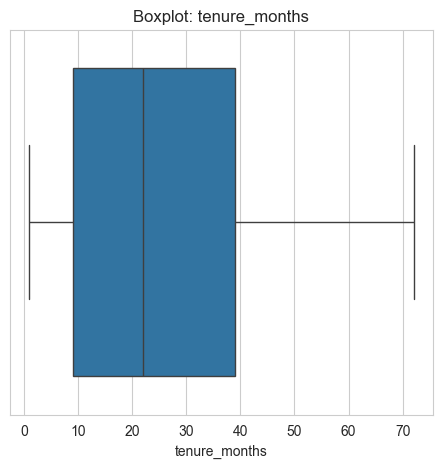

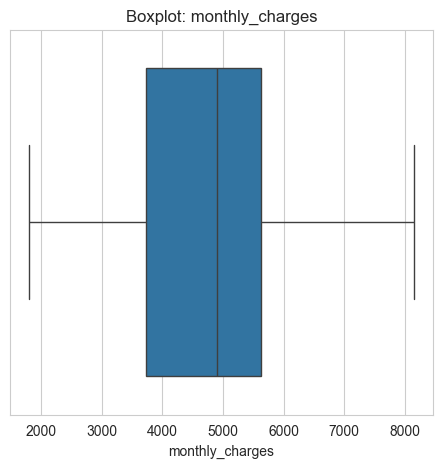

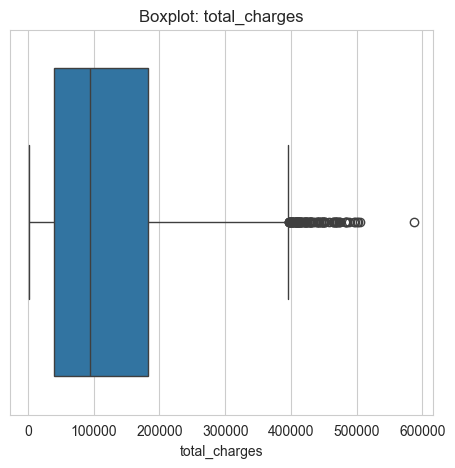

In [56]:
# Plot distribution using IQR
for col in numeric_cols:
    plt.figure(figsize=(12,5))

    # Boxplot
    plt.subplot(1,2,2)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot: {col}')

    plt.show()

**Interpretation of the shapes**

***For tenure_months:***

The box is long: customers vary widely in how long they have stayed.

A slightly longer upper whisker: moderate right skew (more new than long-term customers).

***For monthly_charges***

The whiskers are short to mean that charges don't vary drastically.

Slight left skew (from skewness results), meaning:

***For total charges***

Heavy right skew: Most customers have small to medium total charges.

A few customers accumulate extremely large total costs over time.

This shape shows a long-tail distribution.

# ** 📈Part 5: Visualizations (15 points)**

---



Create at least 8 professional visualizations that tell the data story. Choose the right chart types, add clear labels, and make insights immediately visible.

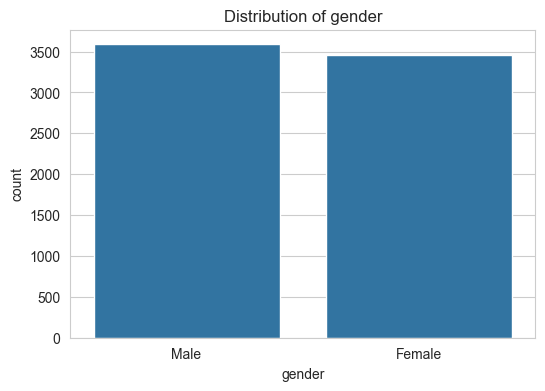

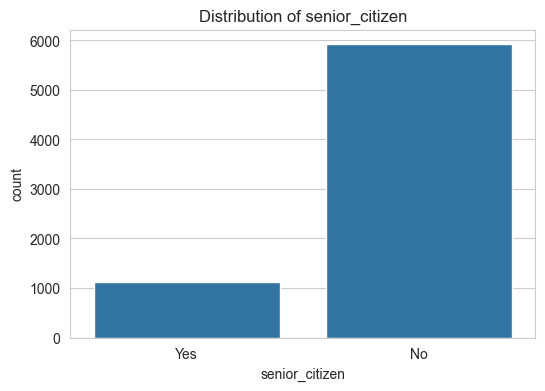

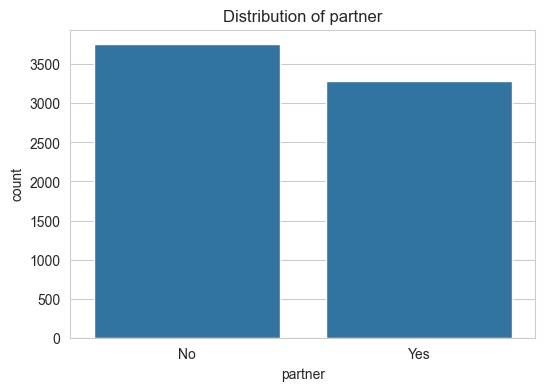

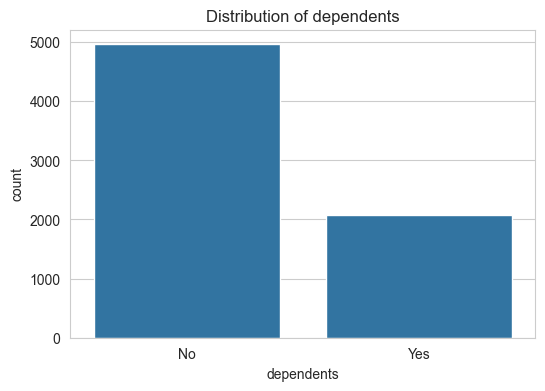

In [57]:
# Bar CHarts for Categorical Variables
for col in demographic_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(data=df, x=col)
    plt.title(f"Distribution of {col}")
    plt.show()

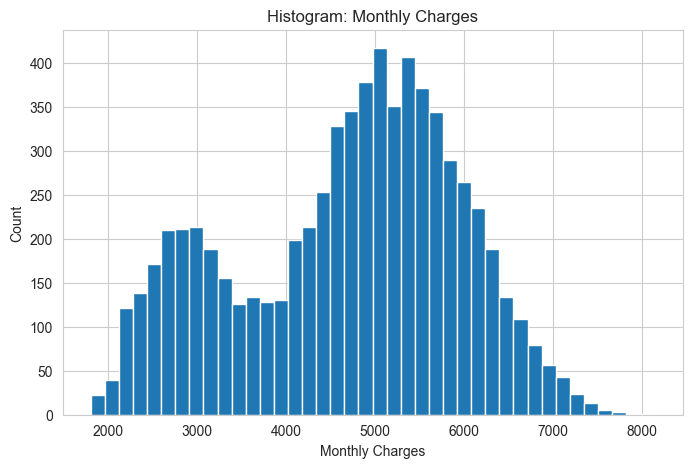

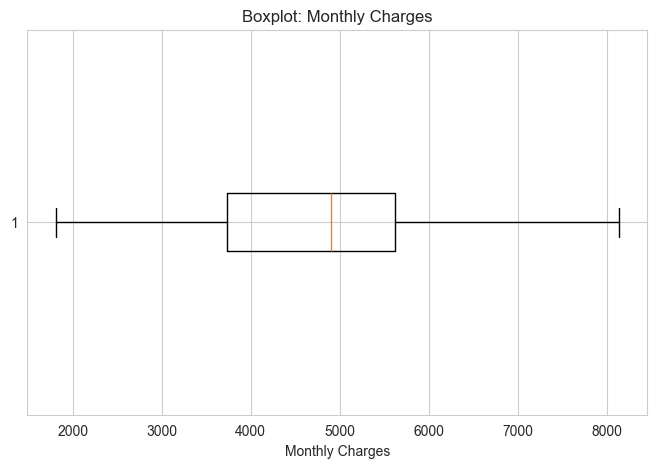

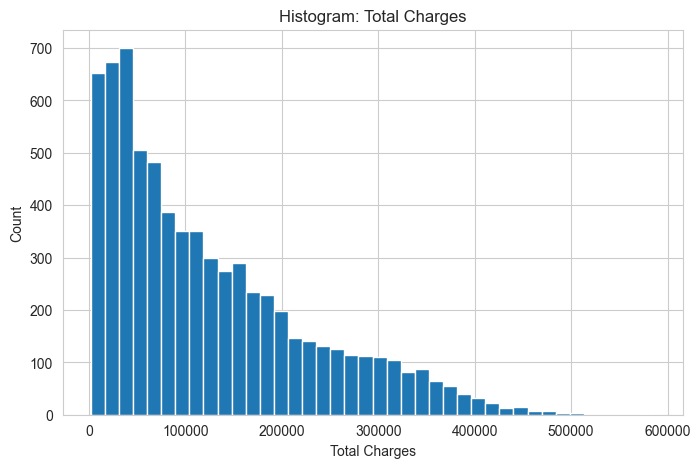

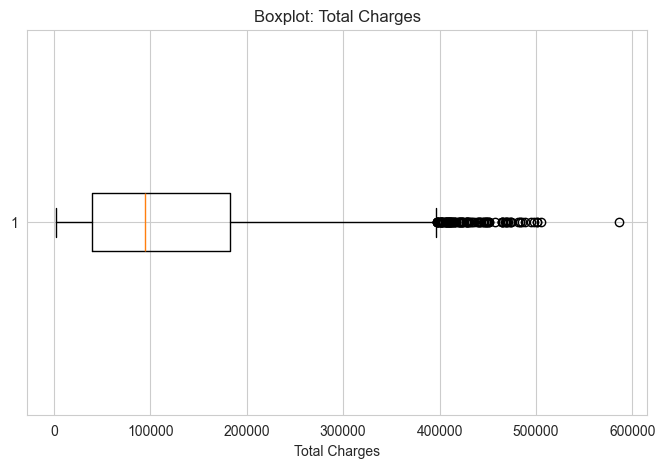

In [58]:
# Visualizations for financial distributions
plt.figure(figsize=(8,5))
plt.hist(df["monthly_charges"].dropna(), bins=40)
plt.title("Histogram: Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,5))
plt.boxplot(df["monthly_charges"].dropna(), vert=False)
plt.title("Boxplot: Monthly Charges")
plt.xlabel("Monthly Charges")
plt.show()

plt.figure(figsize=(8,5))
plt.hist(df["total_charges"].dropna(), bins=40)
plt.title("Histogram: Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8,5))
plt.boxplot(df["total_charges"].dropna(), vert=False)
plt.title("Boxplot: Total Charges")
plt.xlabel("Total Charges")
plt.show()

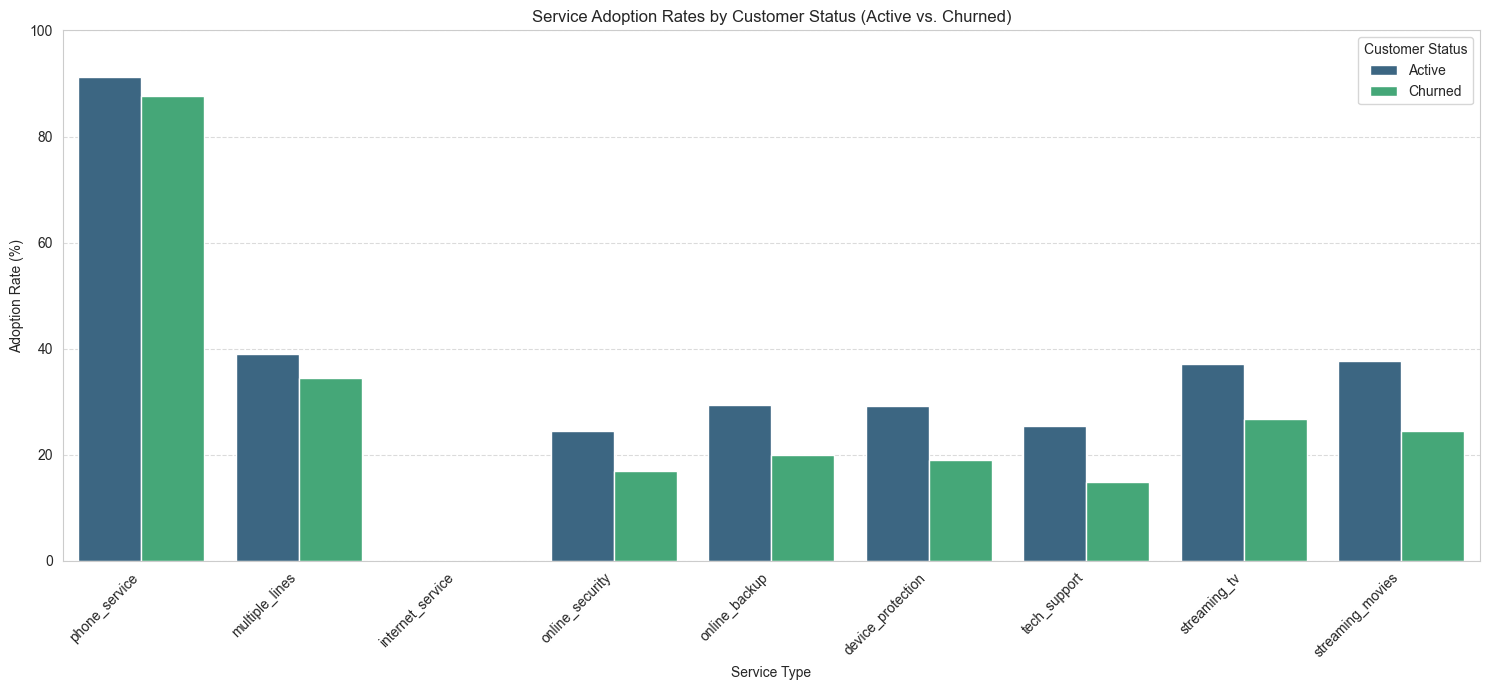

In [59]:
# Reset the index for easier plotting
service_churn_plot = service_churn.reset_index()

# Melt the DataFrame to long format for Seaborn
service_churn_melted = service_churn_plot.melt(id_vars="customer_status", var_name="Service", value_name="Adoption_Rate")

plt.figure(figsize=(15, 7))
sns.barplot(data=service_churn_melted, x="Service", y="Adoption_Rate", hue="customer_status", palette="viridis")
plt.title("Service Adoption Rates by Customer Status (Active vs. Churned)")
plt.xlabel("Service Type")
plt.ylabel("Adoption Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.legend(title="Customer Status")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

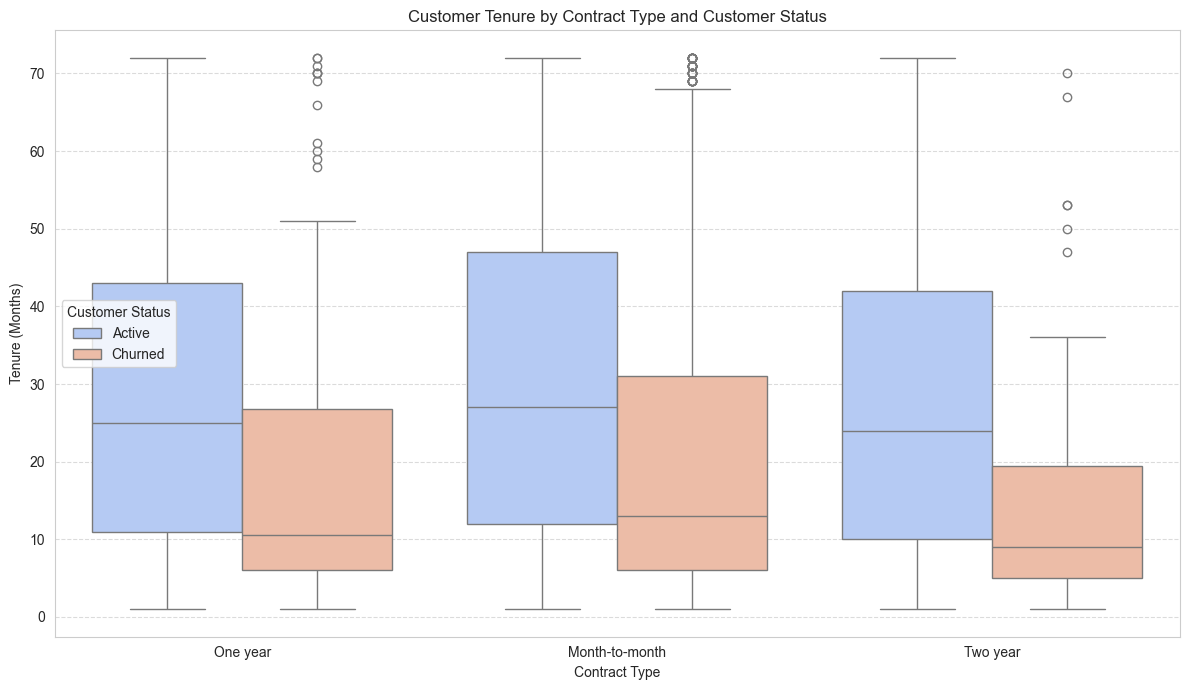

In [60]:
# Visualize tenure distribution by customer status and contract type
plt.figure(figsize=(12, 7))
sns.boxplot(data=df, x="contract_type", y="tenure_months", hue="customer_status", palette="coolwarm")
plt.title("Customer Tenure by Contract Type and Customer Status")
plt.xlabel("Contract Type")
plt.ylabel("Tenure (Months)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

Churn rate by Payment Method:
customer_status               Active    Churned
payment_method                                 
Bank transfer (automatic)  72.136422  27.863578
Credit card (automatic)    73.139378  26.860622
Electronic check           65.539984  34.460016
Mailed check               73.186120  26.813880


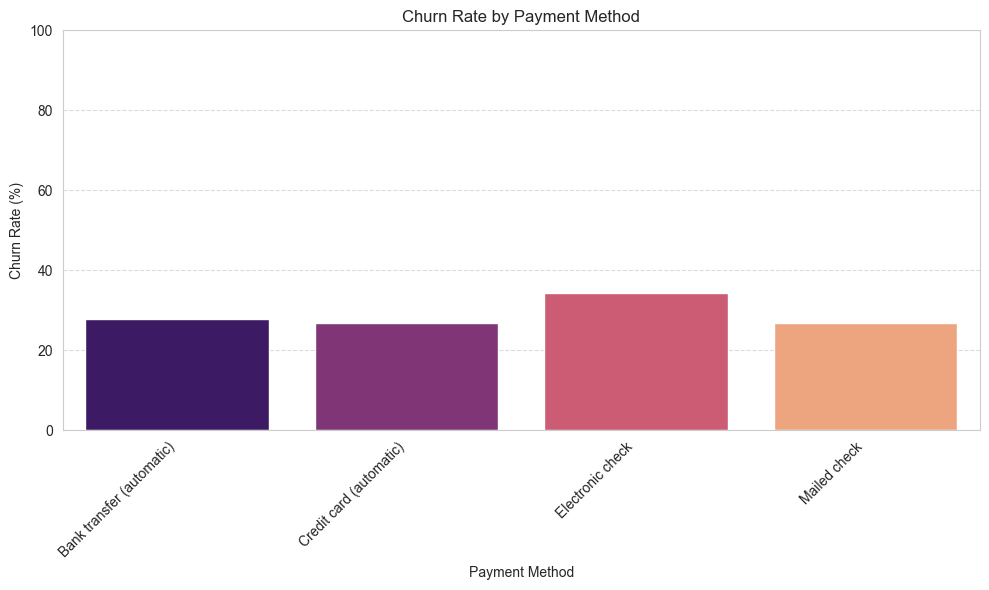

In [61]:
# Analyze churn rate by payment method
payment_churn = pd.crosstab(df["payment_method"], df["customer_status"], normalize="index") * 100
print("Churn rate by Payment Method:")
print(payment_churn)

# Visualize the churn rate by payment method
plt.figure(figsize=(10, 6))
sns.barplot(x=payment_churn.index, y=payment_churn["Churned"], palette="magma")
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Churn rate by Contract Type:
customer_status     Active    Churned
contract_type                        
Month-to-month   56.411582  43.588418
One year         84.451827  15.548173
Two year         89.760479  10.239521


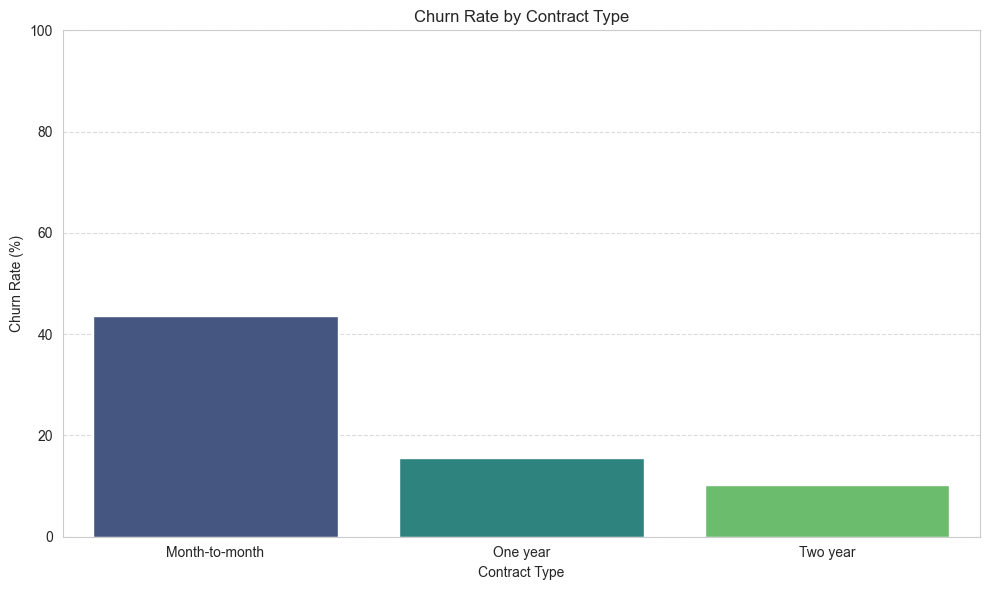

In [62]:
# Analyze churn rate by contract type
contract_churn = pd.crosstab(df["contract_type"], df["customer_status"], normalize="index") * 100
print("Churn rate by Contract Type:")
print(contract_churn)

# Visualize the churn rate by contract type
plt.figure(figsize=(10, 6))
sns.barplot(x=contract_churn.index, y=contract_churn["Churned"], palette="viridis")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

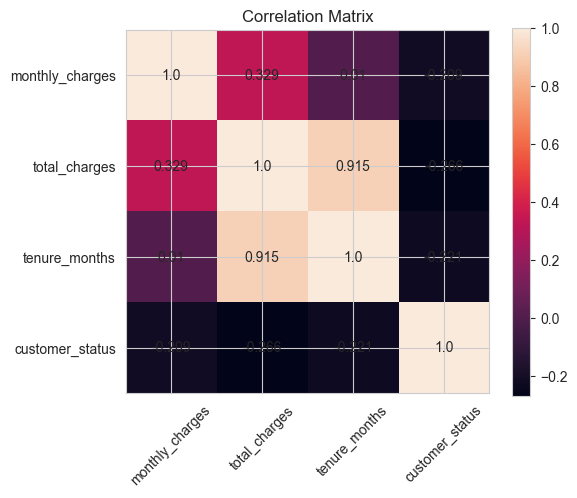

In [63]:
# Correlation Matrix
plt.figure(figsize=(6,5))
plt.imshow(corr_matrix, interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45)
plt.yticks(range(len(corr_cols)), corr_cols)

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        plt.text(
            j, i,
            str(round(corr_matrix.iloc[i,j], 3)),
            ha="center", va="center"
        )

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## Filter Month-to-Month Customers

In [64]:
# Filter the main DataFrame `df` to create a new DataFrame `df_month_to_month` containing only customers with "Month-to-month" contracts, then display its head and shape for verification.
df_month_to_month = df[df["contract_type"] == "Month-to-month"]
print("First 5 rows of df_month_to_month:")
print(df_month_to_month.head())
print(f"\nShape of df_month_to_month: {df_month_to_month.shape}")

First 5 rows of df_month_to_month:
  customer_id  gender senior_citizen partner dependents  tenure_months  \
1   CUST00002  Female             No     Yes         No             10   
3   CUST00004  Female             No      No         No             70   
4   CUST00005    Male            Yes      No         No             36   
5   CUST00006    Male             No     Yes         No              5   
7   CUST00008  Female             No      No         No             61   

  phone_service multiple_lines internet_service      online_security  ...  \
1           Yes            Yes              DSL                   No  ...   
3           Yes             No              DSL                   No  ...   
4           Yes            Yes      Fiber optic                  Yes  ...   
5           Yes             No               No  No internet service  ...   
7           Yes            Yes      Fiber optic                  Yes  ...   

              payment_method monthly_charges total_charge

Visually compare the service adoption rates between active and churned customers in month-to-month contracts



In [71]:
# service_adoption_mtm_plot = service_adoption_mtm.reset_index()
# service_adoption_mtm_melted = service_adoption_mtm_plot.melt(id_vars="customer_status", var_name="Service", value_name="Adoption_Rate")

# plt.figure(figsize=(15, 7))
# sns.barplot(data=service_adoption_mtm_melted, x="Service", y="Adoption_Rate", hue="customer_status", palette="coolwarm")
# plt.title("Service Adoption Rates for Month-to-Month Customers (Active vs. Churned)")
# plt.xlabel("Service Type")
# plt.ylabel("Adoption Rate (%)")
# plt.xticks(rotation=45, ha="right")
# plt.ylim(0, 100)
# plt.legend(title="Customer Status")
# plt.grid(axis="y", linestyle="--", alpha=0.7)
# plt.tight_layout()
# plt.show()

Calculate the churn rate for each payment method within the `df_month_to_month` DataFrame.



In [72]:
payment_churn_mtm = pd.crosstab(df_month_to_month["payment_method"], df_month_to_month["customer_status"], normalize="index") * 100
print("Churn rate by Payment Method for Month-to-Month Customers:")
print(payment_churn_mtm)

Churn rate by Payment Method for Month-to-Month Customers:
customer_status               Active    Churned
payment_method                                 
Bank transfer (automatic)  58.037825  41.962175
Credit card (automatic)    61.192214  38.807786
Electronic check           50.414469  49.585531
Mailed check               59.450172  40.549828


Visualize the churn rate by payment method for month-to-month customers

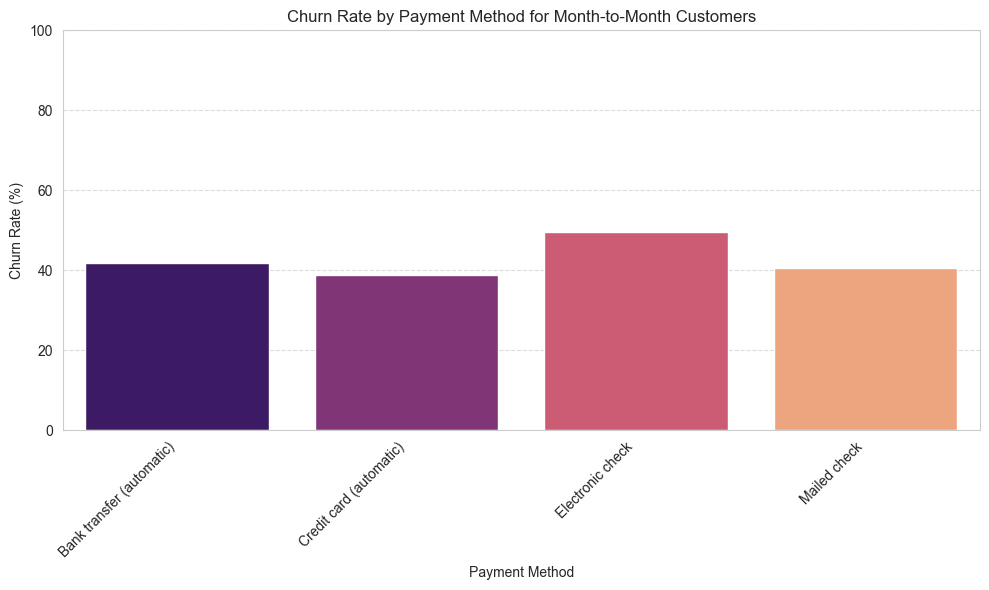

In [67]:
plt.figure(figsize=(10, 6))
sns.barplot(x=payment_churn_mtm.index, y=payment_churn_mtm["Churned"], palette="magma")
plt.title("Churn Rate by Payment Method for Month-to-Month Customers")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Visually represent the distribution of "monthly_charges" for active and churned customers within month-to-month contracts



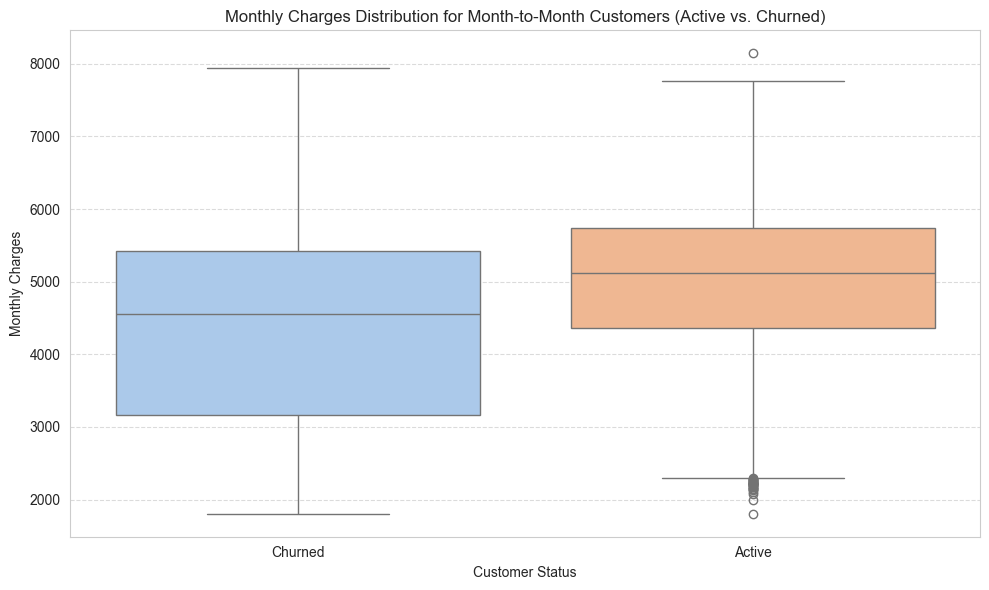

In [73]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_month_to_month, x="customer_status", y="monthly_charges", palette="pastel")
plt.title("Monthly Charges Distribution for Month-to-Month Customers (Active vs. Churned)")
plt.xlabel("Customer Status")
plt.ylabel("Monthly Charges")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# ** 💡Part 6: Business Insights & Recommendations (15 points)**

---



Translate your analysis into action. Deliver 5-7 specific findings and 5+ actionable recommendations with rationale, expected impact, and priority levels.

**Business Insights**

i.	Customer Tenure Is the Most Powerful Indicator of Retention
Customers with higher tenure are significantly less likely to churn.
Tenure_months shows a very strong positive correlation (0.91) with total revenue generated.

New customers (0–12 months) form the highest churn-risk group.


ii.	High Monthly Charges Increase the Likelihood of Churn
Monthly charges distribution shows many customers pay on the higher end.
Customers with high monthly bills and short tenure are particularly vulnerable.
Those using multiple premium services without commitment contracts churn the most.


iii.	Month-to-Month Contract Customers Have the Highest Churn Rates.
Annual and two-year contracts demonstrate substantially higher retention.
Customers on flexible contracts are more sensitive to price changes and service quality.


iv.	Service Bundle Usage Predicts Churn Behavior.

Customers with only phone_service show higher churn.
Those with bundles like multiple_lines + streaming services tend to remain longer.


Add-on services increase loyalty only when bundled, not sold individually.


v.	Electronic Payments Strongly Reduce Churn.

Customers using auto-pay, credit card, or paperless billing are more consistent and loyal.

Cash/physical payments correlate with higher churn.


vi.	Customer Demographics Reveal Vulnerable Segments

Senior citizens and single-person households churn at higher rates.

This segment often has lower service adoption and higher price sensitivity.



**Recommendations**
Improve Retention Among First-Year Customers

Introduce a “First-Year Loyalty Accelerator” for new customers, free one month usage if the customer takes annual package, and exclusive customer support for new joiners.


Address Churn Driven by High Monthly Charges

Implement personalized pricing by lowering cost of custom bundles, allowing for usage-based pricing for low-data customers.


Long-Term Contract Adoption

Offer incentives, discounts, and loyalty points for switching to annual subscriptions.

Introduce contract renewal reminders and benefits for early and automatic renewals.

Service Bundling Strategies

Create attractive combined bundles such as: multiple-lines subscribers, Phone + internet and many more to encourage consumption of more than one product.
Accomodate phone-only subscription for users who do not need the internet by offering low-cost data add-ons.

Encourage Electronic and Auto-Pay Billing like mobile payment and internet banking.

Model special packages for seniors and households

Discounts when multiple users share a plan to encourage users with dependents and partners to subscribe


Implement Predictive Churn Modeling to help flag customers about to churn and offer targeted marketing towards them.


**Priority Levels versus expected impact**  

Targeting early-tenure customers  - Reduced churn in first 12 months

Promoting long-term contracts - Increased customer lifetime value (CLV)

Improving service bundles  - Higher ARPU and stronger loyalty   

Encouraging auto-pay -Reduced involuntary churn

Fixing data issues  - Improved trust and billing satisfaction

Senior & single-household targeting - Lower churn for vulnerable groups

Predictive modeling  - Data-driven retention automation
